In [28]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial import cKDTree


In [38]:
# Parameters
h = 1
n = 100
reference_density = 1000
particle_mass = 10
dt = 0.01

In [39]:
def get_neighbors(positions, h):
    tree = cKDTree(positions)
    neighbors = tree.query_ball_point(positions, r=2*h)
    return neighbors


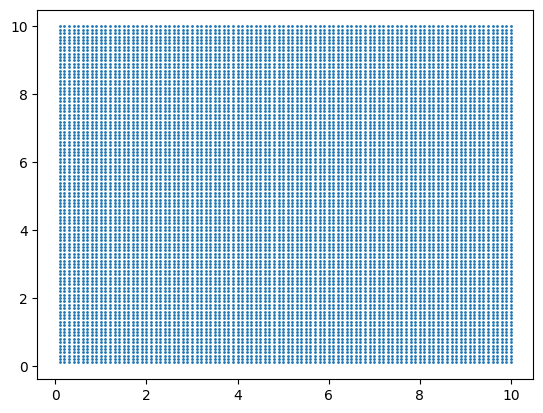

In [45]:
def initalize_particles():
    velocities = np.zeros((n**2, 2))

    x = np.linspace(0.1, n * 0.1, n)
    positions = np.array(np.meshgrid(x, x)).T.reshape(-1,2)

    densities = np.ones(n**2) * reference_density

    return positions, velocities, densities

positions, velocities, densities = initalize_particles()

plt.scatter(positions[:,0], positions[:, 1], s=1)
plt.show()

In [ ]:
# Start off with simple cubic spline kernel
def kernel(position1, position2):
    r = np.linalg.norm(position1, position2)
    q = r / h
    if q < 1:
        fq = 1 - 3 / 2 * q**2 + 3 / 4 * q**3
    elif q < 2:
        fq = 1 / 4 * (2 - q)**3
    else:
        fq = 0
    W = 10 * fq / (7 * np.pi * h**2)
    return W

def kernel_gradient(position1, position2):
    r = np.linalg.norm(position1, position2)
    q = r / h
    if q < 1:
        fpq = -3 * q + 9 / 4 * q**2
    elif q < 2:
        fpq = -3 / 4 * (2 - q)**2
    else:
        fpq = 0
    dWdr = 10 * fpq / (7 * np.pi * h**3)
    nabla_W = dWdr * (position1 - position2) / r
    return nabla_W


In [ ]:
def compute_density_change(positions, velocities, neighbors):
    densities_changes = np.zeros(len(neighbors))
    for particle_index, particle_neighbors in enumerate(neighbors):
        for neighbor_index in particle_neighbors:
            if particle_index == neighbor_index:
                continue
            velocity_dir = velocities[particle_index] - velocities[neighbor_index]
            nabla_W = kernel_gradient(positions[particle_index], positions[neighbor_index])
            densities_changes[particle_index] += particle_mass * np.dot(velocity_dir, nabla_W)
    return densities_changes